# Análise Exploratória — Stack Overflow Developer Survey

**Objetivo:** fazer a primeira "radiografia" da base escolhida — tipagem das variáveis (contínuas x categóricas),
medidas de tendência central e dispersão, nulos, outliers e forma da distribuição (normal ou não) — para orientar
as próximas etapas do trabalho.

## Base e recorte

- **Fonte:** Stack Overflow Developer Survey (edição com módulo de IA/AI Agents), arquivos `survey_results_public.csv`
  (49.191 respostas, 172 colunas) e `survey_results_schema.csv` (dicionário oficial das perguntas).
- **Recorte de linhas:** `MainBranch == "I am a developer by profession"` → mantém só quem se declara desenvolvedor
  profissional (37.467 respostas, ~76% da base). Isso remove estudantes, hobbistas e ex-desenvolvedores, que
  distorcem as perguntas de carreira, mercado de trabalho e remuneração.
- **Valores faltantes:** a pesquisa é paginada/opcional — respostas em branco vêm gravadas como a string literal
  `"NA"`, não como célula vazia. Tratamos isso na leitura (`na_values=["NA"]`).

## Critério de seleção das colunas

A base tem 172 colunas, mas boa parte é de **múltipla escolha** ("selecione todas que se aplicam", ex.: linguagens,
plataformas, frameworks) ou de **ranking composto** (`TechEndorse_*`, `JobSatPoints_*`), com valores separados por
`;` — isso exige um parsing próprio (explosão de listas) que foge do escopo desta primeira análise exploratória.

Por isso priorizamos **20 colunas de resposta única** (numéricas ou categóricas simples), formando um eixo temático
coerente — *perfil profissional, remuneração/satisfação e adoção/percepção de IA*:


| Coluna | O que significa | Tipo escolhido |
|---|---|---|
| `Age` | Faixa etária | Categórica ordinal |
| `EdLevel` | Nível de formação mais alto concluído | Categórica ordinal |
| `Employment` | Situação de emprego atual | Categórica nominal |
| `WorkExp` | Anos de experiência profissional em programação | Contínua (numérica) |
| `YearsCode` | Anos totais programando (incluindo estudo) | Contínua (numérica) |
| `DevType` | Cargo/função atual | Categórica nominal |
| `OrgSize` | Tamanho da empresa (nº de funcionários) | Categórica ordinal |
| `ICorPM` | Contribuidor individual ou gestor de pessoas | Categórica nominal |
| `RemoteWork` | Modelo de trabalho (remoto/híbrido/presencial) | Categórica nominal |
| `Country` | País de residência | Categórica nominal (alta cardinalidade) |
| `Industry` | Setor/indústria em que atua | Categórica nominal |
| `JobSat` | Satisfação com o cargo atual (escala 1-10) | Contínua/ordinal discreta |
| `ConvertedCompYearly` | Remuneração anual total, convertida para USD | Contínua (numérica) |
| `AIThreat` | Percepção de a IA ameaçar o próprio emprego | Categórica nominal |
| `AISelect` | Uso de ferramentas de IA no desenvolvimento | Categórica nominal |
| `AISent` | Sentimento em relação ao uso de IA no trabalho | Categórica ordinal |
| `AIAcc` | Confiança na precisão das saídas de IA | Categórica ordinal |
| `AIComplex` | Percepção de quão bem a IA lida com tarefas complexas | Categórica ordinal |
| `AIAgents` | Uso de agentes de IA no trabalho | Categórica nominal |
| `SOVisitFreq` | Frequência de visita ao Stack Overflow | Categórica ordinal |

**Resumo:** 4 variáveis contínuas (`WorkExp`, `YearsCode`, `JobSat`, `ConvertedCompYearly`) e 16 categóricas.

## 1. Carga, filtro e seleção de colunas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

COLS = [
    "ResponseId", "MainBranch",
    "Age", "EdLevel", "Employment", "WorkExp", "YearsCode", "DevType", "OrgSize",
    "ICorPM", "RemoteWork", "Country", "Industry", "JobSat", "ConvertedCompYearly",
    "AIThreat", "AISelect", "AISent", "AIAcc", "AIComplex", "AIAgents", "SOVisitFreq",
]

df_raw = pd.read_csv("survey_results_public.csv", usecols=COLS, na_values=["NA"], low_memory=False)
print("Linhas antes do filtro:", len(df_raw))

df = df_raw[df_raw["MainBranch"] == "I am a developer by profession"].drop(columns=["MainBranch"]).reset_index(drop=True)
print("Linhas depois do filtro (devs profissionais):", len(df))
df.head()

Linhas antes do filtro: 49191
Linhas depois do filtro (devs profissionais): 37467


,ResponseId,Age,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,AIThreat,Country,SOVisitFreq,AISelect,AISent,AIAcc,AIComplex,AIAgents,ConvertedCompYearly,JobSat
0,1,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,8.0,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,Fintech,I'm not sure,Ukraine,A few times per week,"Yes, I use AI tools monthly or infrequently",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,"Yes, I use AI agents at work monthly or infreq...",61256.0,10.0
1,2,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,2.0,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",Retail and Consumer Services,I'm not sure,Netherlands,Multiple times per day,"Yes, I use AI tools weekly",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,"No, and I don't plan to",104413.0,9.0
2,3,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",10.0,12.0,"Developer, front-end",NaN,NaN,NaN,Software Development,No,Ukraine,A few times per week,"Yes, I use AI tools daily",Favorable,Somewhat trust,Neither good or bad at handling complex tasks,"Yes, I use AI agents at work weekly",53061.0,8.0
3,4,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,4.0,5.0,"Developer, back-end","10,000 or more employees",Individual contributor,Remote,Retail and Consumer Services,No,Ukraine,A few times per month or weekly,"Yes, I use AI tools weekly",Favorable,Somewhat trust,Bad at handling complex tasks,"Yes, I use AI agents at work monthly or infreq...",36197.0,6.0
4,5,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",21.0,22.0,Engineering manager,NaN,NaN,NaN,Software Development,No,Ukraine,A few times per month or weekly,"Yes, I use AI tools weekly",Favorable,Neither trust nor distrust,"Good, but not great at handling complex tasks","No, and I don't plan to",60000.0,7.0


In [2]:
CONTINUOUS = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly"]
CATEGORICAL = [c for c in df.columns if c not in CONTINUOUS + ["ResponseId"]]

for c in CONTINUOUS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Contínuas:", CONTINUOUS)
print("Categóricas:", CATEGORICAL)
df.dtypes

Contínuas: ['WorkExp', 'YearsCode', 'JobSat', 'ConvertedCompYearly']
Categóricas: ['Age', 'EdLevel', 'Employment', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'Industry', 'AIThreat', 'Country', 'SOVisitFreq', 'AISelect', 'AISent', 'AIAcc', 'AIComplex', 'AIAgents']


ResponseId               int64
Age                        str
EdLevel                    str
Employment                 str
WorkExp                float64
YearsCode              float64
DevType                    str
OrgSize                    str
ICorPM                     str
RemoteWork                 str
Industry                   str
AIThreat                   str
Country                    str
SOVisitFreq                str
AISelect                   str
AISent                     str
AIAcc                      str
AIComplex                  str
AIAgents                   str
ConvertedCompYearly    float64
JobSat                 float64
dtype: object

## 2. Radiografia geral — nulos por coluna

In [3]:
null_report = pd.DataFrame({
    "tipo": ["contínua" if c in CONTINUOUS else "categórica" for c in df.columns if c != "ResponseId"],
    "n_nulos": df.drop(columns="ResponseId").isna().sum(),
    "% nulos": (df.drop(columns="ResponseId").isna().mean() * 100).round(1),
}).sort_values("% nulos", ascending=False)
null_report

,tipo,n_nulos,% nulos
ConvertedCompYearly,contínua,17272,46.1
AIAgents,categórica,12684,33.9
SOVisitFreq,categórica,12104,32.3
AIAcc,categórica,11728,31.3
AIComplex,categórica,11734,31.3
AISent,categórica,11614,31.0
AISelect,categórica,11422,30.5
JobSat,contínua,10797,28.8
Country,categórica,10292,27.5
ICorPM,categórica,9606,25.6


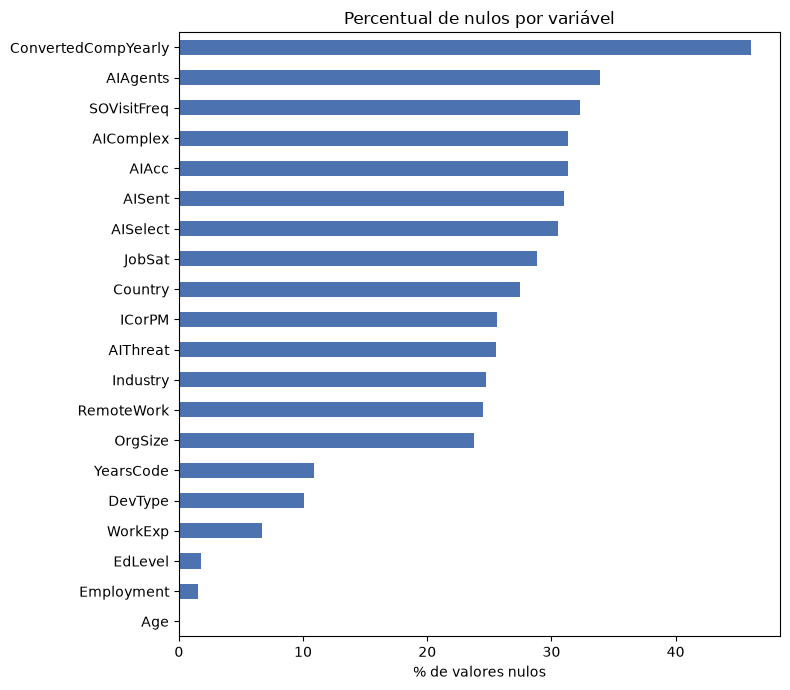

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
null_report.sort_values("% nulos")["% nulos"].plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("% de valores nulos")
ax.set_title("Percentual de nulos por variável")
plt.tight_layout()
plt.show()

## 3. Variáveis contínuas

Estatísticas descritivas (média, mediana, quartis, desvio padrão) e forma da distribuição.

In [5]:
desc = df[CONTINUOUS].describe(percentiles=[.25, .5, .75]).T
desc["mediana"] = df[CONTINUOUS].median()
desc["assimetria"] = df[CONTINUOUS].skew()
desc["curtose"] = df[CONTINUOUS].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,mediana,assimetria,curtose
WorkExp,34947.0,12.926431,9.988109,1.0,5.0,10.0,19.0,100.0,10.0,1.311326,3.124939
YearsCode,33380.0,17.339245,11.065558,1.0,9.0,15.0,25.0,100.0,15.0,1.081578,1.757284
JobSat,26670.0,7.201950,1.997245,0.0,6.0,8.0,8.0,10.0,8.0,-1.014195,1.300888
ConvertedCompYearly,20195.0,100965.931518,309024.794966,1.0,41775.5,77760.0,124029.0,33552715.0,77760.0,73.693310,7215.369886


### Histogramas

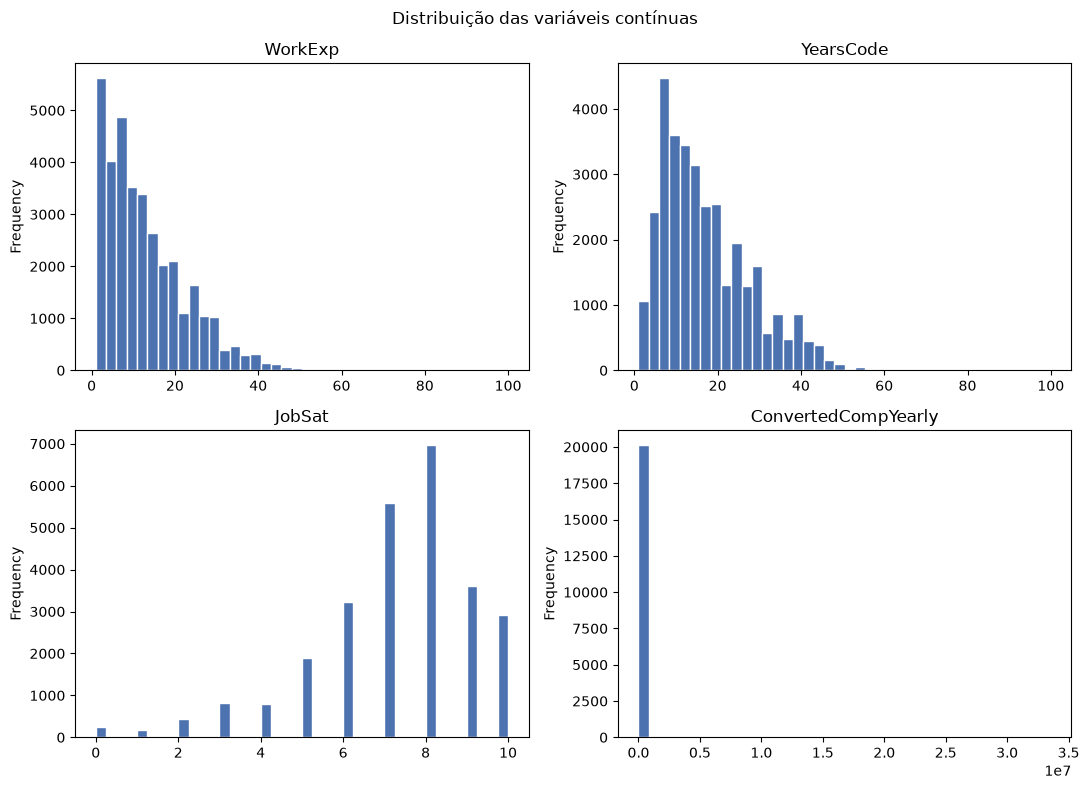

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, c in zip(axes.flat, CONTINUOUS):
    df[c].dropna().plot(kind="hist", bins=40, ax=ax, color="#4C72B0", edgecolor="white")
    ax.set_title(c)
    ax.set_xlabel("")
plt.suptitle("Distribuição das variáveis contínuas")
plt.tight_layout()
plt.show()

### Boxplots — dispersão e outliers

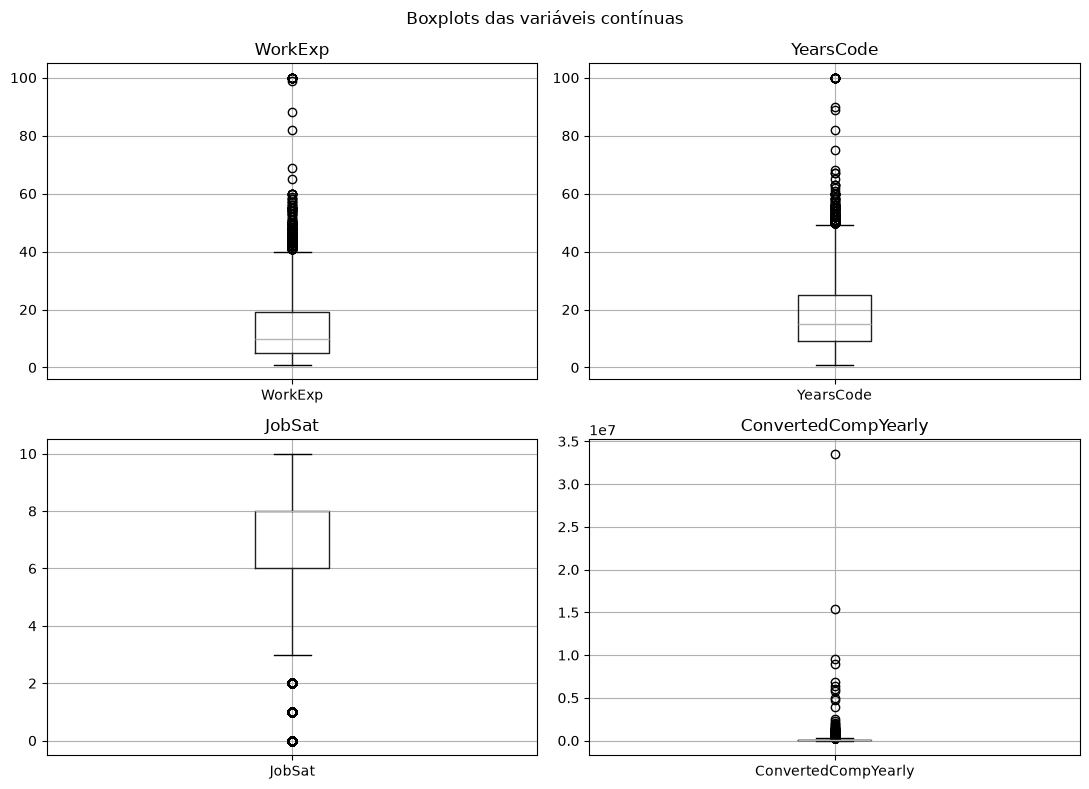

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, c in zip(axes.flat, CONTINUOUS):
    df.boxplot(column=c, ax=ax)
    ax.set_title(c)
plt.suptitle("Boxplots das variáveis contínuas")
plt.tight_layout()
plt.show()

### Outliers pelo critério de IQR (1.5×)

In [8]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < low) | (s > high)).sum()
    return pd.Series({"limite_inf": low, "limite_sup": high, "n_outliers": n_out, "% outliers": round(100 * n_out / len(s), 1)})

outlier_report = pd.DataFrame({c: iqr_outliers(df[c]) for c in CONTINUOUS}).T
outlier_report

,limite_inf,limite_sup,n_outliers,% outliers
WorkExp,-16.00,40.00,444.0,1.3
YearsCode,-15.00,49.00,200.0,0.6
JobSat,3.00,11.00,846.0,3.2
ConvertedCompYearly,-81604.75,247409.25,875.0,4.3


### Teste de normalidade

Usamos o teste de D'Agostino-Pearson (`scipy.stats.normaltest`), adequado para amostras grandes (o Shapiro-Wilk só é recomendado até ~5.000 observações). H0: a amostra vem de uma distribuição normal.

In [9]:
norm_rows = []
for c in CONTINUOUS:
    s = df[c].dropna()
    stat, p = stats.normaltest(s)
    norm_rows.append({"variável": c, "n": len(s), "estatística": round(stat, 1), "p-valor": p, "é normal? (alpha=0.05)": "Não" if p < 0.05 else "Sim"})
pd.DataFrame(norm_rows)

,variável,n,estatística,p-valor,é normal? (alpha=0.05)
0,WorkExp,34947,8653.4,0.0,Não
1,YearsCode,33380,5768.4,0.0,Não
2,JobSat,26670,3958.9,0.0,Não
3,ConvertedCompYearly,20195,72695.5,0.0,Não


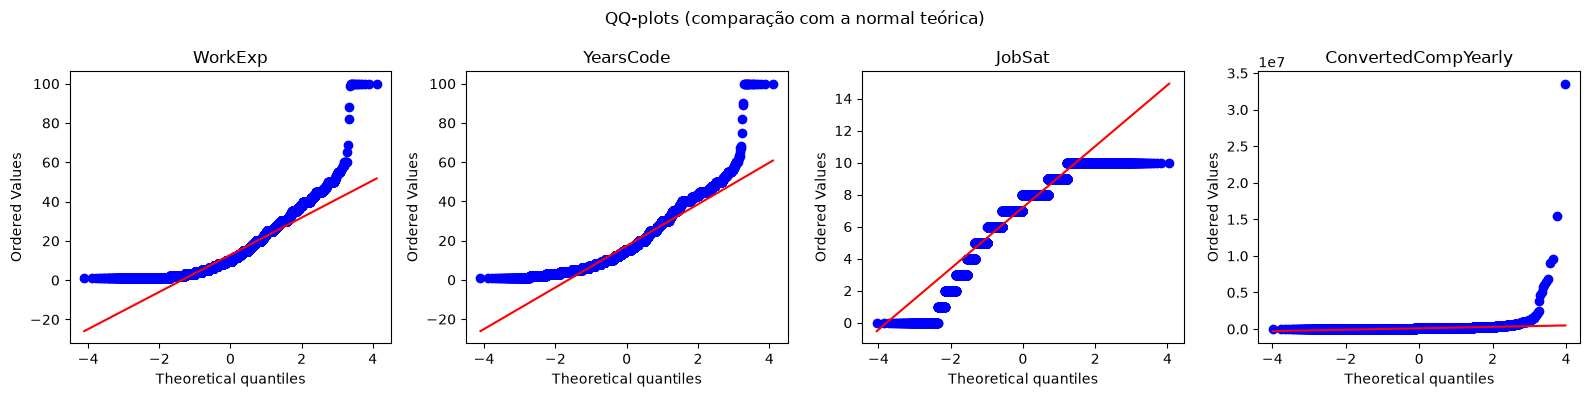

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, CONTINUOUS):
    stats.probplot(df[c].dropna(), dist="norm", plot=ax)
    ax.set_title(c)
plt.suptitle("QQ-plots (comparação com a normal teórica)")
plt.tight_layout()
plt.show()

## 4. Variáveis categóricas

Frequência das categorias (contagem e %). Para variáveis de alta cardinalidade (`Country`, `DevType`, `Industry`)
mostramos as 8 categorias mais frequentes + "Outros".

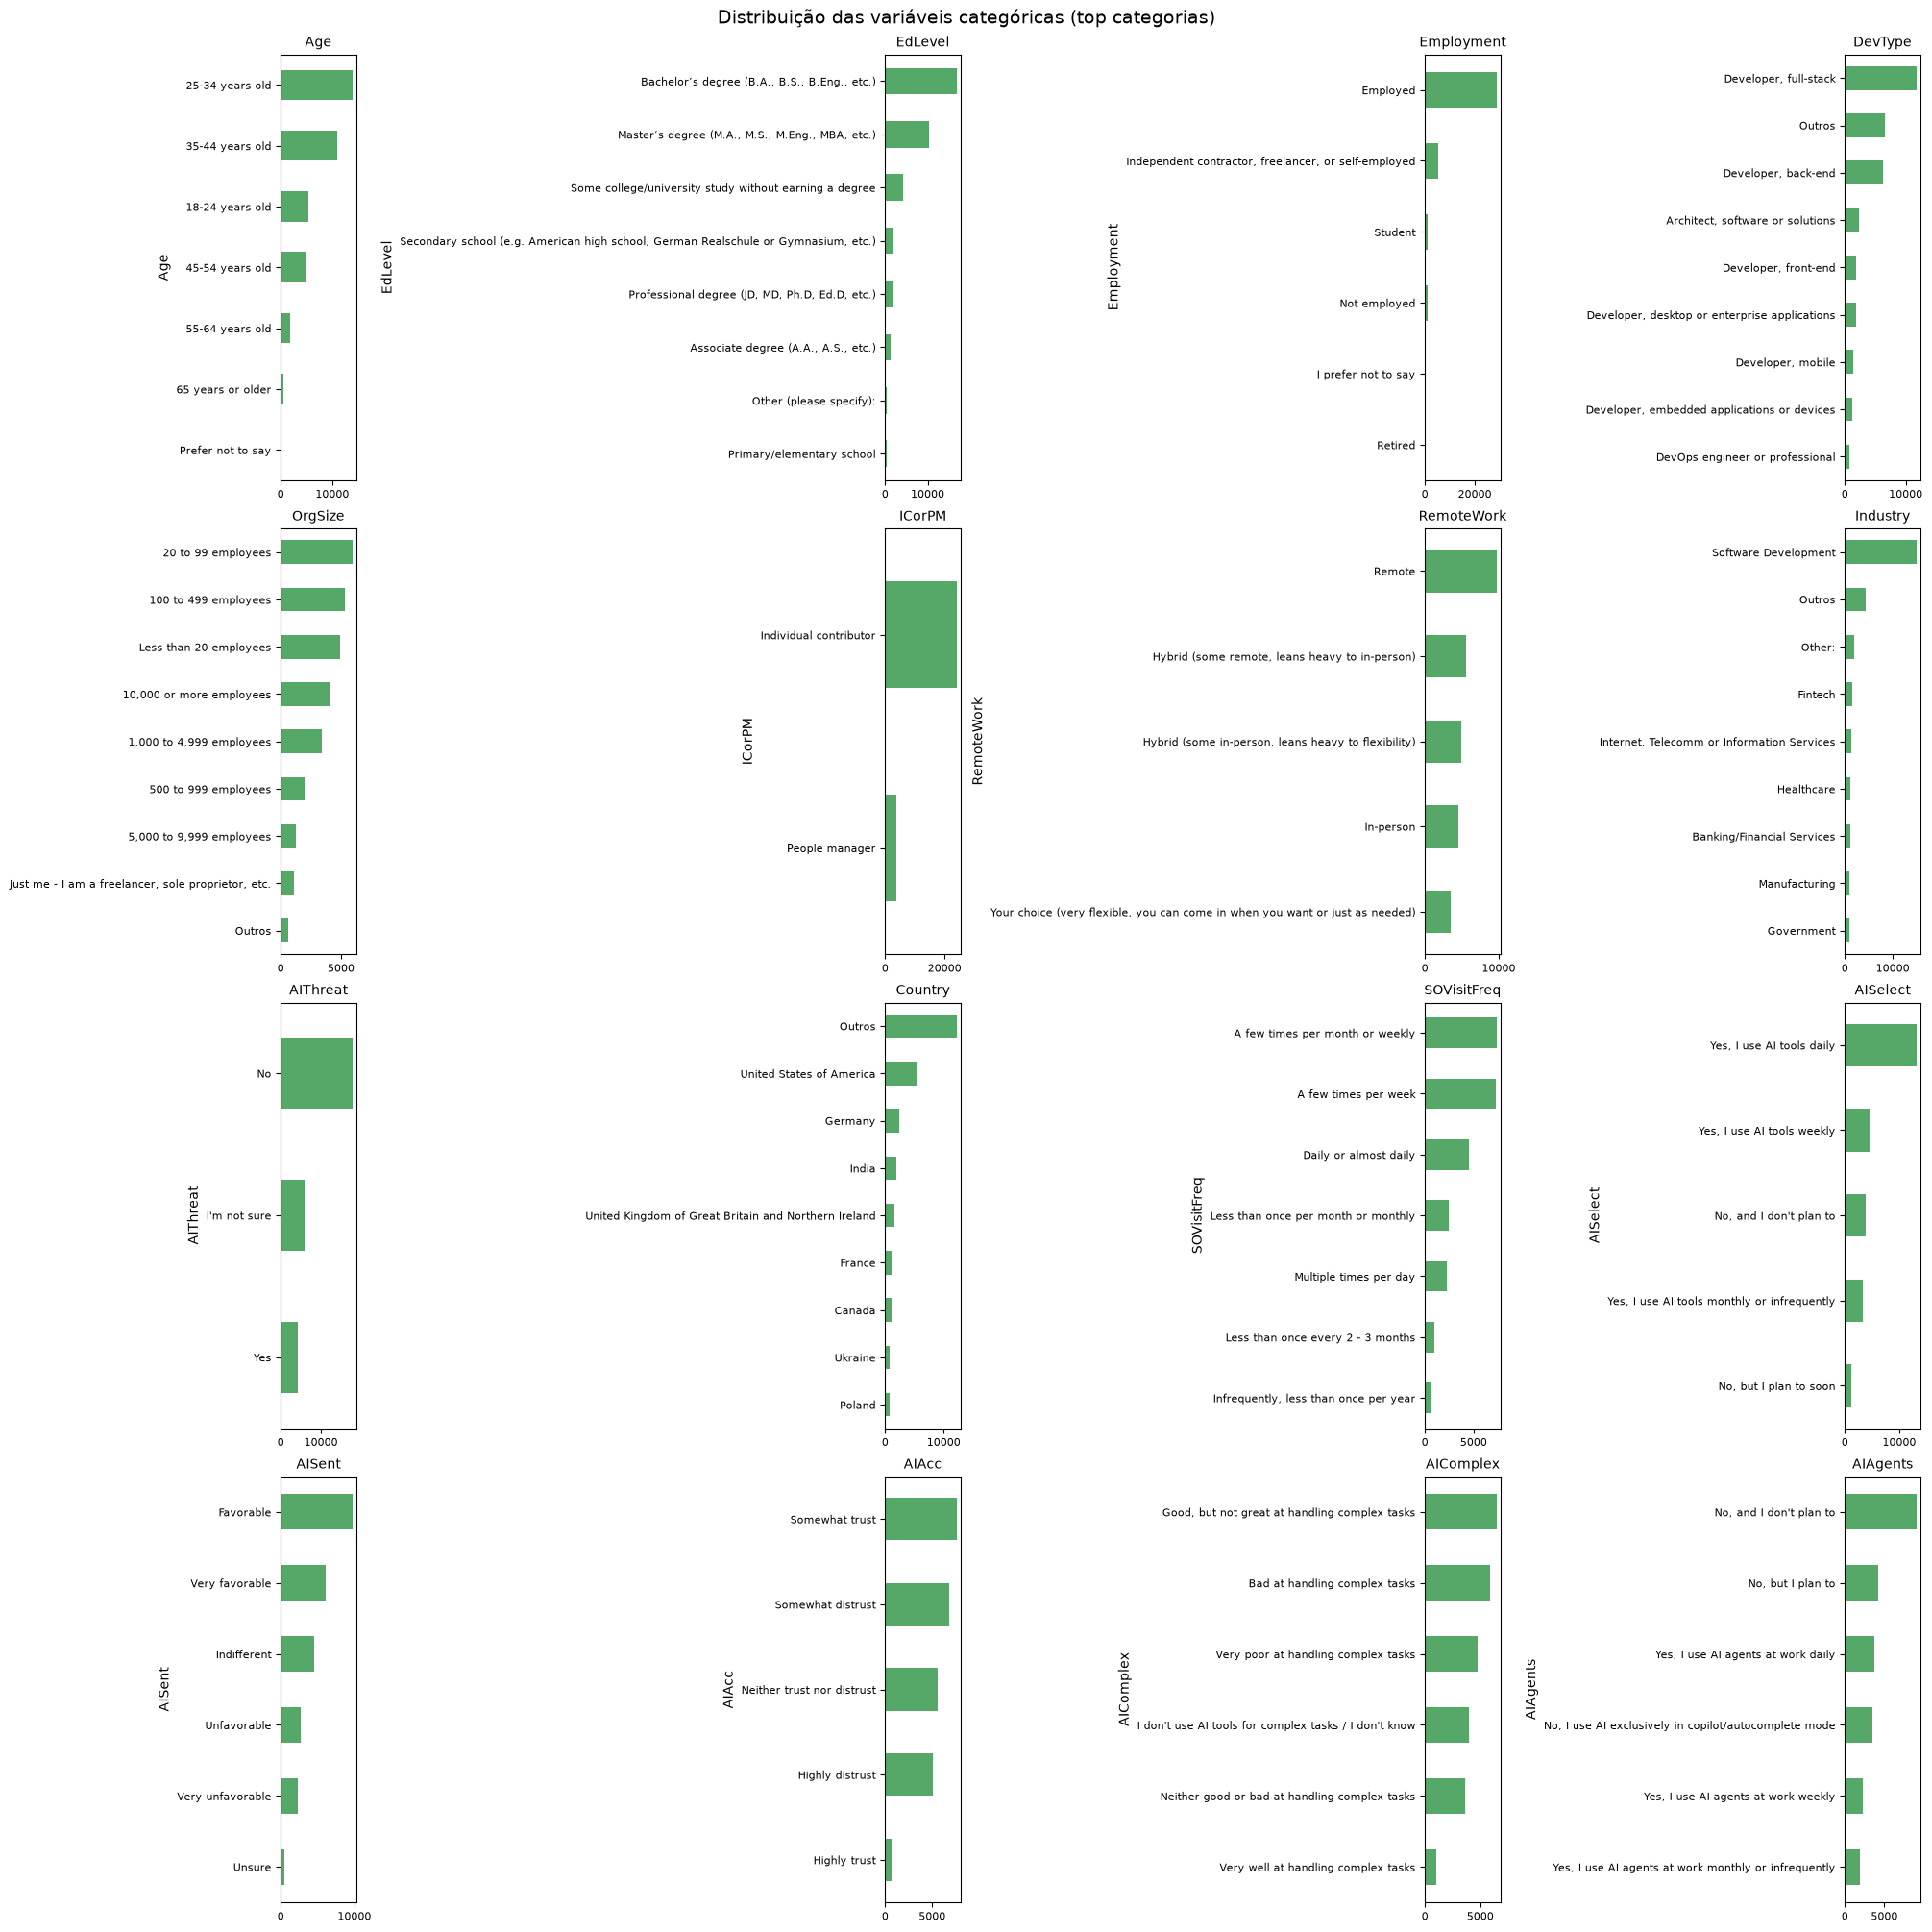

In [11]:
def top_categories(s, n=8):
    vc = s.value_counts(dropna=True)
    if len(vc) > n:
        top = vc.iloc[:n]
        outros = pd.Series({"Outros": vc.iloc[n:].sum()})
        vc = pd.concat([top, outros])
    return vc

fig, axes = plt.subplots(4, 4, figsize=(20, 20), constrained_layout=True)
for ax, c in zip(axes.flat, CATEGORICAL):
    vc = top_categories(df[c])
    vc.sort_values().plot(kind="barh", ax=ax, color="#55A868")
    ax.set_title(c, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Distribuição das variáveis categóricas (top categorias)", fontsize=14)
plt.show()

In [12]:
cat_summary = []
for c in CATEGORICAL:
    vc = df[c].value_counts(dropna=True)
    cat_summary.append({
        "variável": c,
        "n_categorias": df[c].nunique(dropna=True),
        "categoria_mais_frequente": vc.index[0],
        "% da moda": round(100 * vc.iloc[0] / df[c].notna().sum(), 1),
        "% nulos": round(100 * df[c].isna().mean(), 1),
    })
pd.DataFrame(cat_summary)

,variável,n_categorias,categoria_mais_frequente,% da moda,% nulos
0,Age,7,25-34 years old,37.2,0.0
1,EdLevel,8,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",45.9,1.8
2,Employment,6,Employed,78.0,1.5
3,DevType,32,"Developer, full-stack",35.0,10.1
4,OrgSize,9,20 to 99 employees,20.8,23.8
5,ICorPM,2,Individual contributor,86.7,25.6
6,RemoteWork,5,Remote,34.4,24.5
7,Industry,15,Software Development,53.1,24.7
8,AIThreat,3,No,63.9,25.5
9,Country,168,United States of America,20.4,27.5


## 5. Síntese dos achados

- **Tipagem:** 4 variáveis contínuas (`WorkExp`, `YearsCode`, `JobSat`, `ConvertedCompYearly`) e 16 categóricas
  (a maioria nominal, algumas ordinais como `Age`, `EdLevel`, `OrgSize`, `AISent`, `AIAcc`, `AIComplex`, `SOVisitFreq`).
- **Nulos:** concentrados nas perguntas que aparecem mais tarde no formulário (remuneração, IA, país) — ver seção 2.
- **Distribuição:** nenhuma das 4 variáveis contínuas segue distribuição normal pelo teste de D'Agostino-Pearson
  (p-valor ≈ 0 em todas) — todas assimétricas à direita (cauda longa), o que já aparece nos histogramas e é
  esperado para dados de experiência/tempo/remuneração.
- **Outliers:** ver tabela da seção 3 (critério IQR 1.5×) — `ConvertedCompYearly` é a variável com mais outliers,
  coerente com a cauda longa de salários muito altos.
- **Categóricas:** ver gráficos de barras da seção 4 para a categoria dominante de cada variável (ex.: concentração
  em "Individual contributor", "Employed", uso majoritário de IA, etc.).
